# FIFA World Cup 2026 – Objective 2

This notebook is my first test of the variables chosen for Objectives 2.1 and 2.2. I used the FBref match results, cleaned the data and checked whether the variables have a relationship with the results. I then used them in a basic linear regression model.

At this stage I am testing **two variables for each model**. The final assessment needs eight for each one.


## Getting the files ready

I kept the three CSV files in the same folder as this notebook.

In [1]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import re

HERE = Path.cwd()
output_dir = HERE / "outputs"
output_dir.mkdir(exist_ok=True)

RAW_FILE = HERE / "Objective2_RAW_FBref_104_Matches.csv"
OBJ21_FILE = HERE / "Objective2_1_104_Matches.csv"
OBJ22_FILE = HERE / "Objective2_2_208_TeamMatches.csv"

# Extra source files for my other two 2.2 variables
AGE_FILE = HERE / "Age.csv"
RESULTS_FILE = HERE / "International_results.csv"


## 1. Loading the data

First I checked the sizes of the datasets and the columns in the raw FBref file.

In [2]:
raw = pd.read_csv(RAW_FILE)
obj21 = pd.read_csv(OBJ21_FILE)
obj22 = pd.read_csv(OBJ22_FILE)

print("\n================ DATA COLLECTION ================")
print("Raw FBref matches:", raw.shape)
print("Objective 2.1 dataset:", obj21.shape)
print("Objective 2.2 dataset:", obj22.shape)

print("\nRaw FBref columns:")
print(raw.columns.tolist())



================ DATA COLLECTION ================
Raw FBref matches: (104, 13)
Objective 2.1 dataset: (104, 15)
Objective 2.2 dataset: (208, 12)

Raw FBref columns:
['Round', 'Wk', 'Day', 'Date', 'Time', 'Home', 'Score', 'Away', 'Attendance', 'Venue', 'Referee', 'Match Report', 'Notes']


## 2. Cleaning the match results

The FBref scores are stored as text, so I separated them into goals for each team. I also tidied the team names and saved a cleaned copy.

In [3]:
raw["Date"] = pd.to_datetime(raw["Date"], errors="coerce")

# Remove the country-code text included by FBref
# Examples:
# "Mexico mx" -> "Mexico"
# "za South Africa" -> "South Africa"
def clean_home_team(name):
    if pd.isna(name):
        return name
    return re.sub(r"\s+[a-z]{2,3}$", "", str(name)).strip()

def clean_away_team(name):
    if pd.isna(name):
        return name
    return re.sub(r"^[a-z]{2,3}\s+", "", str(name)).strip()

raw["Home_Team"] = raw["Home"].apply(clean_home_team)
raw["Away_Team"] = raw["Away"].apply(clean_away_team)

# Extract the match score.
# This also handles knockout scores such as "(3) 1–1 (4)".
score_parts = raw["Score"].astype(str).str.extract(
    r"(?:\(\d+\)\s*)?(\d+)\s*[–-]\s*(\d+)(?:\s*\(\d+\))?"
)

raw["Home_Goals"] = pd.to_numeric(score_parts[0], errors="coerce")
raw["Away_Goals"] = pd.to_numeric(score_parts[1], errors="coerce")

# Goal difference for Objective 2.1 target
raw["Goal_Difference"] = raw["Home_Goals"] - raw["Away_Goals"]

# Keep the useful raw fields for evidence / checking
raw_clean = raw[
    [
        "Round",
        "Date",
        "Home_Team",
        "Away_Team",
        "Home_Goals",
        "Away_Goals",
        "Goal_Difference",
    ]
].copy()

print("\n================ RAW DATA WRANGLING ================")
print("Missing values after score/date cleaning:")
print(raw_clean.isna().sum())

print("\nCleaned raw sample:")
print(raw_clean.head())

raw_clean.to_csv(
    output_dir / "cleaned_raw_104_matches.csv",
    index=False
)



================ RAW DATA WRANGLING ================
Missing values after score/date cleaning:
Round              0
Date               0
Home_Team          0
Away_Team          0
Home_Goals         0
Away_Goals         0
Goal_Difference    0
dtype: int64

Cleaned raw sample:
         Round       Date       Home_Team     Away_Team  Home_Goals  \
0  Group stage 2026-06-11          Mexico  South Africa           2   
1  Group stage 2026-06-11  Korea Republic       Czechia           2   
2  Group stage 2026-06-12          Canada   Bosnia–Herz           1   
3  Group stage 2026-06-12             USA      Paraguay           4   
4  Group stage 2026-06-13           Qatar   Switzerland           1   

   Away_Goals  Goal_Difference  
0           0                2  
1           1                1  
2           1                0  
3           1                3  
4           1                0  


## 3. Preparing the data for 2.1

For this part I am predicting the goal difference between the two teams. I checked the selected columns, missing values and correlation with the actual goal difference.

In [4]:
obj21["Date"] = pd.to_datetime(obj21["Date"], errors="coerce")

obj21_columns = [
    "Match_ID",
    "Date",
    "Team_A",
    "Team_B",
    "X1_PreMatch_GD_Difference",
    "X2_PreMatch_Win_Rate_Difference",
    "Y_Actual_Goal_Difference",
]

data21 = obj21[obj21_columns].copy()

# Ensure statistical variables are numeric
numeric21 = [
    "X1_PreMatch_GD_Difference",
    "X2_PreMatch_Win_Rate_Difference",
    "Y_Actual_Goal_Difference",
]

for col in numeric21:
    data21[col] = pd.to_numeric(data21[col], errors="coerce")

print("\n================ OBJECTIVE 2.1 WRANGLING ================")
print("Missing values:")
print(data21.isna().sum())

# Some teams have no previous tournament match, so their first values are missing.

# I leave these missing values out of the scatterplot test.
scatter21 = data21.dropna(
    subset=[
        "X1_PreMatch_GD_Difference",
        "X2_PreMatch_Win_Rate_Difference",
        "Y_Actual_Goal_Difference",
    ]
).copy()

print("\nRows available for Objective 2.1 scatter testing:", len(scatter21))

print("\nObjective 2.1 descriptive statistics:")
print(
    scatter21[
        [
            "X1_PreMatch_GD_Difference",
            "X2_PreMatch_Win_Rate_Difference",
            "Y_Actual_Goal_Difference",
        ]
    ].describe().round(3)
)

print("\nObjective 2.1 correlations with Goal Difference:")
corr21 = scatter21[
    [
        "X1_PreMatch_GD_Difference",
        "X2_PreMatch_Win_Rate_Difference",
        "Y_Actual_Goal_Difference",
    ]
].corr()

print(corr21["Y_Actual_Goal_Difference"].round(3))

scatter21.to_csv(
    output_dir / "objective2_1_scatter_ready.csv",
    index=False
)



================ OBJECTIVE 2.1 WRANGLING ================
Missing values:
Match_ID                            0
Date                                0
Team_A                              0
Team_B                              0
X1_PreMatch_GD_Difference          24
X2_PreMatch_Win_Rate_Difference    24
Y_Actual_Goal_Difference            0
dtype: int64

Rows available for Objective 2.1 scatter testing: 80

Objective 2.1 descriptive statistics:
       X1_PreMatch_GD_Difference  X2_PreMatch_Win_Rate_Difference  \
count                     80.000                           80.000   
mean                       0.315                            0.045   
std                        2.108                            0.441   
min                       -6.000                           -1.000   
25%                       -0.750                            0.000   
50%                        0.708                            0.000   
75%                        1.500                            0.271   
m

## 4. Scatterplots for 2.1

I plotted each variable against the actual goal difference to see whether there is a visible linear pattern.

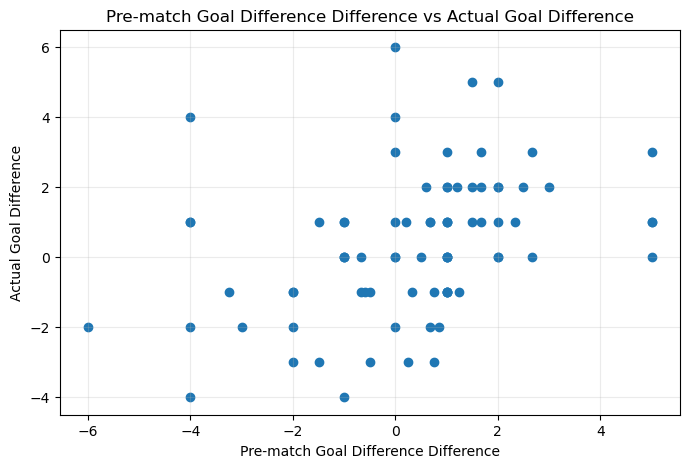

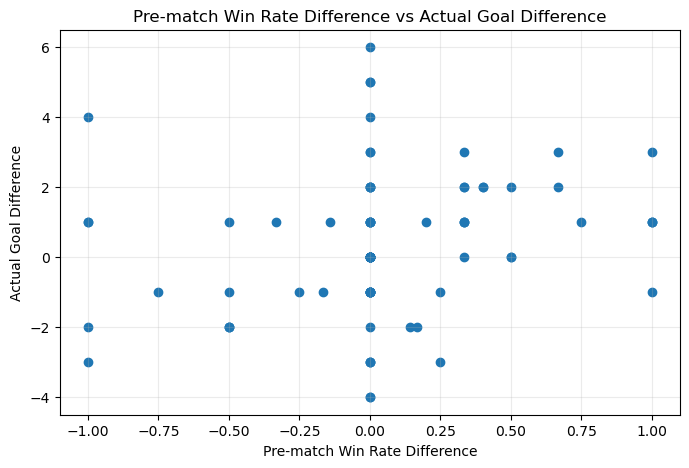

In [5]:
variables21 = [
    (
        "Pre-match Goal Difference Difference",
        "X1_PreMatch_GD_Difference",
    ),
    (
        "Pre-match Win Rate Difference",
        "X2_PreMatch_Win_Rate_Difference",
    ),
]

for label, x_col in variables21:
    plt.figure(figsize=(8, 5))
    plt.scatter(
        scatter21[x_col],
        scatter21["Y_Actual_Goal_Difference"]
    )

    plt.xlabel(label)
    plt.ylabel("Actual Goal Difference")
    plt.title(f"{label} vs Actual Goal Difference")
    plt.grid(alpha=0.25)

    safe = "".join(ch if ch.isalnum() else "_" for ch in label)

    plt.savefig(
        output_dir / f"Objective2_1_scatter_{safe}.png",
        dpi=200,
        bbox_inches="tight",
    )
    plt.show()


## 5. Preparing the data for 2.2

This model predicts how many goals one team scores in a match. The two variables are the team's previous average goals and the opponent's previous average goals conceded.

In [6]:
obj22["Date"] = pd.to_datetime(obj22["Date"], errors="coerce")

obj22_columns = [
    "TeamMatch_ID",
    "Match_ID",
    "Date",
    "Team",
    "Opponent",
    "X1_Team_PreMatch_Avg_Goals_Scored",
    "X2_Opponent_PreMatch_Avg_Goals_Conceded",
    "Y_Actual_Team_Goals",
]

data22 = obj22[obj22_columns].copy()

numeric22 = [
    "X1_Team_PreMatch_Avg_Goals_Scored",
    "X2_Opponent_PreMatch_Avg_Goals_Conceded",
    "Y_Actual_Team_Goals",
]

for col in numeric22:
    data22[col] = pd.to_numeric(data22[col], errors="coerce")

print("\n================ OBJECTIVE 2.2 WRANGLING ================")
print("Missing values:")
print(data22.isna().sum())

scatter22 = data22.dropna(
    subset=[
        "X1_Team_PreMatch_Avg_Goals_Scored",
        "X2_Opponent_PreMatch_Avg_Goals_Conceded",
        "Y_Actual_Team_Goals",
    ]
).copy()

print("\nRows available for Objective 2.2 scatter testing:", len(scatter22))

print("\nObjective 2.2 descriptive statistics:")
print(
    scatter22[
        [
            "X1_Team_PreMatch_Avg_Goals_Scored",
            "X2_Opponent_PreMatch_Avg_Goals_Conceded",
            "Y_Actual_Team_Goals",
        ]
    ].describe().round(3)
)

print("\nObjective 2.2 correlations with Team Goals:")
corr22 = scatter22[
    [
        "X1_Team_PreMatch_Avg_Goals_Scored",
        "X2_Opponent_PreMatch_Avg_Goals_Conceded",
        "Y_Actual_Team_Goals",
    ]
].corr()

print(corr22["Y_Actual_Team_Goals"].round(3))

scatter22.to_csv(
    output_dir / "objective2_2_scatter_ready.csv",
    index=False
)



================ OBJECTIVE 2.2 WRANGLING ================
Missing values:
TeamMatch_ID                                0
Match_ID                                    0
Date                                        0
Team                                        0
Opponent                                    0
X1_Team_PreMatch_Avg_Goals_Scored          48
X2_Opponent_PreMatch_Avg_Goals_Conceded    48
Y_Actual_Team_Goals                         0
dtype: int64

Rows available for Objective 2.2 scatter testing: 160

Objective 2.2 descriptive statistics:
       X1_Team_PreMatch_Avg_Goals_Scored  \
count                            160.000   
mean                               1.728   
std                                1.106   
min                                0.000   
25%                                1.000   
50%                                1.708   
75%                                2.333   
max                                7.000   

       X2_Opponent_PreMatch_Avg_Goals_Conceded  Y_Act

## 6. Scatterplots for 2.2

These scatterplots help me check whether either variable has a useful relationship with goals scored.

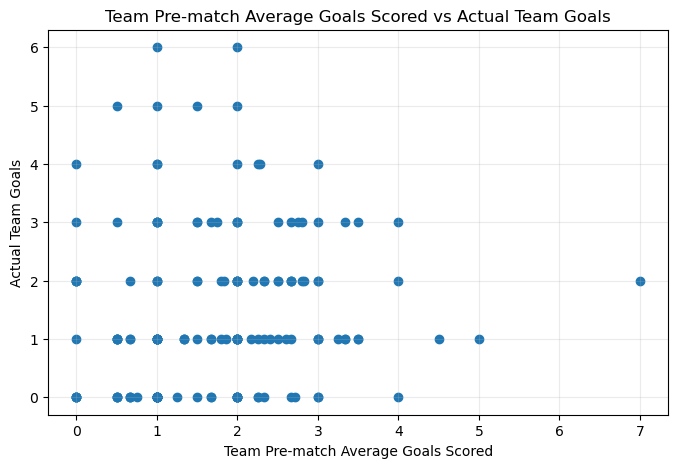

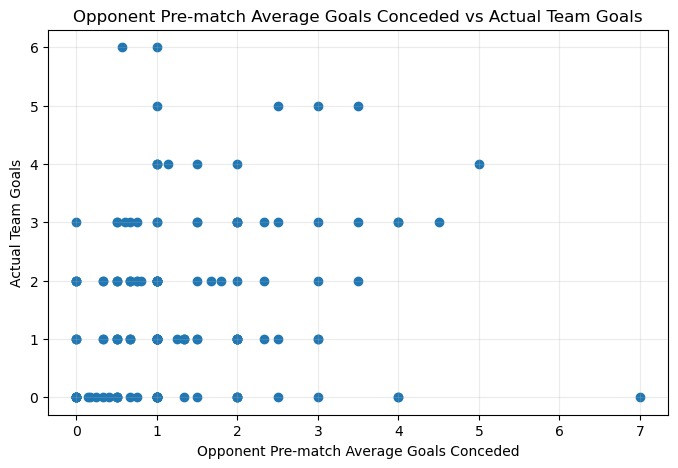

In [7]:
variables22 = [
    (
        "Team Pre-match Average Goals Scored",
        "X1_Team_PreMatch_Avg_Goals_Scored",
    ),
    (
        "Opponent Pre-match Average Goals Conceded",
        "X2_Opponent_PreMatch_Avg_Goals_Conceded",
    ),
]

for label, x_col in variables22:
    plt.figure(figsize=(8, 5))
    plt.scatter(
        scatter22[x_col],
        scatter22["Y_Actual_Team_Goals"]
    )

    plt.xlabel(label)
    plt.ylabel("Actual Team Goals")
    plt.title(f"{label} vs Actual Team Goals")
    plt.grid(alpha=0.25)

    safe = "".join(ch if ch.isalnum() else "_" for ch in label)

    plt.savefig(
        output_dir / f"Objective2_2_scatter_{safe}.png",
        dpi=200,
        bbox_inches="tight",
    )
    plt.show()


## 6A. Two additional Objective 2.2 variables

I also tested **average squad age** and **days since the team's previous international match**. Squad age comes from `Age.csv`; the gap between matches comes from `International_results.csv`. For the match-gap variable, I only look at matches played **before** each 2026 World Cup fixture. The source date for the squad ages still needs checking to confirm it was available before the tournament.

I keep all original CSV files unchanged and save new results in `outputs/`.

In [ ]:
# Prepare my other two predictors for Objective 2.2
import numpy as np

age = pd.read_csv(AGE_FILE, encoding="cp1252")
history = pd.read_csv(RESULTS_FILE, encoding="utf-8-sig")
history["date"] = pd.to_datetime(
    history["date"], format="mixed", dayfirst=True, errors="coerce"
)

# Match the few different spellings used in the files
team_names = {
    "Turkey": "Turkiye",
    "Türkiye": "Turkiye",
    "DR Congo": "Democratic Republic of the Congo",
    "Bosnia and Herzegovina": "Bosnia-Herzegovina",
    "Czech Republic": "Czechia",
    "Curacao": "Curaçao",
    "Korea Republic": "South Korea",
    "USA": "United States"
}

def tidy_team(name):
    name = str(name).strip()
    return team_names.get(name, name)

age["Team_Name"] = age["Club"].map(tidy_team)
data22["Team_Name"] = data22["Team"].map(tidy_team)

# Average age of the team's squad
age["ø-Age"] = pd.to_numeric(age["ø-Age"], errors="coerce")
ages_by_team = age.drop_duplicates("Team_Name").set_index("Team_Name")["ø-Age"]
data22["X3_Avg_Squad_Age"] = data22["Team_Name"].map(ages_by_team)

# Build one list of international match dates for each country
history = history.dropna(subset=["date"]).copy()
history["home_team"] = history["home_team"].map(tidy_team)
history["away_team"] = history["away_team"].map(tidy_team)

home_dates = history[["date", "home_team"]].rename(
    columns={"home_team": "Team_Name"}
)
away_dates = history[["date", "away_team"]].rename(
    columns={"away_team": "Team_Name"}
)
team_dates = pd.concat([home_dates, away_dates], ignore_index=True)
team_dates = team_dates.drop_duplicates(["Team_Name", "date"])
team_dates = team_dates.sort_values(["Team_Name", "date"])

dates_by_team = {
    team: group["date"].to_numpy(dtype="datetime64[ns]")
    for team, group in team_dates.groupby("Team_Name")
}

def days_since_last_game(team, match_date):
    dates = dates_by_team.get(team)
    if dates is None or pd.isna(match_date):
        return np.nan
    current_date = np.datetime64(match_date, "ns")
    position = np.searchsorted(dates, current_date, side="left") - 1
    if position < 0:
        return np.nan
    return int((current_date - dates[position]) / np.timedelta64(1, "D"))

data22["X4_Days_Since_Previous_Match"] = [
    days_since_last_game(team, date)
    for team, date in zip(data22["Team_Name"], data22["Date"])
]

new_cols = ["X3_Avg_Squad_Age", "X4_Days_Since_Previous_Match"]
print("Missing values in the two new variables:")
print(data22[new_cols].isna().sum())
print("\nDescriptive statistics:")
print(data22[new_cols].describe().round(3))
print("\nFirst five rows:")
print(data22[["Team", "Date"] + new_cols].head())


In [ ]:
# Test all four of my 2.2 variables separately
# A missing value in one variable does not remove a row for the other plots
variable_tests = [
    ("Team Pre-match Average Goals Scored",
     "X1_Team_PreMatch_Avg_Goals_Scored"),
    ("Opponent Pre-match Average Goals Conceded",
     "X2_Opponent_PreMatch_Avg_Goals_Conceded"),
    ("Average Squad Age", "X3_Avg_Squad_Age"),
    ("Days Since Previous International Match", "X4_Days_Since_Previous_Match")
]

corr_results = []
for label, column in variable_tests:
    available = data22[[column, "Y_Actual_Team_Goals"]].dropna()
    r = available[column].corr(available["Y_Actual_Team_Goals"])
    corr_results.append({
        "Variable": label,
        "Rows": len(available),
        "Missing": len(data22) - len(available),
        "Correlation": r
    })

    # The first two plots are already made above. Only save the missing two.
    if column in new_cols:
        plt.figure(figsize=(8, 5))
        plt.scatter(available[column], available["Y_Actual_Team_Goals"], alpha=0.6)
        plt.xlabel(label)
        plt.ylabel("Actual Team Goals")
        plt.title(f"{label} vs Actual Team Goals (r = {r:.3f})")
        plt.grid(alpha=0.25)
        safe = "".join(ch if ch.isalnum() else "_" for ch in label)
        plt.savefig(output_dir / f"Objective2_2_scatter_{safe}.png",
                    dpi=200, bbox_inches="tight")
        plt.show()

correlation_table = pd.DataFrame(corr_results)
print("\nObjective 2.2: all four variable checks")
print(correlation_table.round(3).to_string(index=False))
correlation_table.to_csv(
    output_dir / "Objective2_2_Correlation_Results.csv", index=False
)
data22.drop(columns="Team_Name").to_csv(
    output_dir / "Objective2_2_Four_Variables_Prepared.csv", index=False
)
print("\nNew outputs saved in:", output_dir)


## 7. Quick check

I checked how many rows were available after removing records with missing previous-match information.

In [8]:
print("\n================ FINAL CHECK ================")
print("Original raw matches:", len(raw))
print("Objective 2.1 original rows:", len(obj21))
print("Objective 2.1 scatter-ready rows:", len(scatter21))
print("Objective 2.2 original rows:", len(obj22))
print("Objective 2.2 scatter-ready rows:", len(scatter22))
print("\nAll cleaned CSVs and scatterplots were saved in:")
print(output_dir)



================ FINAL CHECK ================
Original raw matches: 104
Objective 2.1 original rows: 104
Objective 2.1 scatter-ready rows: 80
Objective 2.2 original rows: 208
Objective 2.2 scatter-ready rows: 160

All cleaned CSVs and scatterplots were saved in:
/Users/nimeth/Documents/University Notes and stuff/Charles darwin /July Sem Year 1/Foundation of Data Scinece /Assessment 2/Testing /outputs


## 8. Linear regression and train/test split

I used **80% of the available matches for training and 20% for testing**. The matches are kept in date order, so the model learns from earlier games and is tested on later ones. This is closer to making predictions before future matches. For 2.2, the two rows from the same match stay together in either training or testing.

I compared the predictions using MAE, RMSE and R². Lower MAE and RMSE mean smaller errors, while a higher R² usually means a better fit.

**Limitation:** The first World Cup matches do not have earlier tournament results, so those rows are not included in this first test. To use all 104/208 rows in the final models, I still need suitable pre-tournament data. These are trial models with two variables each, not the final eight-variable models.


In [9]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def train_evaluate(data, feature_cols, target_col, name):
    # Keep matches in order before splitting the data.
    data = data.sort_values(["Match_ID"], kind="stable").copy()
    match_ids = data["Match_ID"].drop_duplicates().to_numpy()
    split_at = int(np.floor(len(match_ids) * 0.80))
    train_match_ids = match_ids[:split_at]
    test_match_ids = match_ids[split_at:]

    train_df = data[data["Match_ID"].isin(train_match_ids)].copy()
    test_df = data[data["Match_ID"].isin(test_match_ids)].copy()

    assert len(set(train_df["Match_ID"]) & set(test_df["Match_ID"])) == 0
    assert len(train_df) and len(test_df)

    X_train = train_df[feature_cols]
    X_test = test_df[feature_cols]
    y_train = train_df[target_col]
    y_test = test_df[target_col]

    model = LinearRegression()
    model.fit(X_train, y_train)
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    metrics = pd.DataFrame([
        {
            "Objective": name, "Split": split,
            "Rows": len(y), "MAE": mean_absolute_error(y, prediction),
            "RMSE": np.sqrt(mean_squared_error(y, prediction)),
            "R2": r2_score(y, prediction)
        }
        for split, y, prediction in [
            ("Train", y_train, train_pred),
            ("Test", y_test, test_pred)
        ]
    ])

    print(f"\\n{name}: {len(train_df)} training rows / {len(test_df)} testing rows")
    print(f"Train matches: {len(train_match_ids)}; Test matches: {len(test_match_ids)}")
    print("Intercept:", round(model.intercept_, 4))
    print("Coefficients:")
    print(pd.Series(model.coef_, index=feature_cols).round(4))
    print("\\nMetrics (lower MAE/RMSE is better; higher R² is better):")
    print(metrics.round(3).to_string(index=False))

    prediction_table = test_df[
        ["Match_ID"] + (["Team"] if "Team" in test_df.columns else ["Team_A", "Team_B"])
    ].copy()
    prediction_table["Actual"] = y_test.to_numpy()
    prediction_table["Predicted"] = test_pred
    prediction_table.to_csv(output_dir / f"{name}_test_predictions.csv", index=False)
    metrics.to_csv(output_dir / f"{name}_train_test_metrics.csv", index=False)

    plt.figure(figsize=(7, 5))
    plt.scatter(y_test, test_pred, alpha=0.7)
    lo = min(y_test.min(), test_pred.min())
    hi = max(y_test.max(), test_pred.max())
    plt.plot([lo, hi], [lo, hi], "--", linewidth=1, label="Perfect predictions")
    plt.xlabel("Actual")
    plt.ylabel("Predicted")
    plt.title(f"{name} — Actual vs Predicted (Test Set)")
    plt.legend()
    plt.grid(alpha=0.2)
    plt.savefig(output_dir / f"{name}_actual_vs_predicted.png", dpi=200, bbox_inches="tight")
    plt.show()
    return model, metrics, prediction_table


## 9. Linear regression for 2.1

I used the goal difference and win-rate differences to predict the match goal difference. I compared the training and testing results to see how well the model worked on matches it had not seen.


\nObjective2_1: 64 training rows / 16 testing rows
Train matches: 64; Test matches: 16
Intercept: 0.4334
Coefficients:
X1_PreMatch_GD_Difference          0.4419
X2_PreMatch_Win_Rate_Difference   -0.5629
dtype: float64
\nMetrics (lower MAE/RMSE is better; higher R² is better):
   Objective Split  Rows   MAE  RMSE     R2
Objective2_1 Train    64 1.456 1.896  0.166
Objective2_1  Test    16 1.573 1.882 -0.494


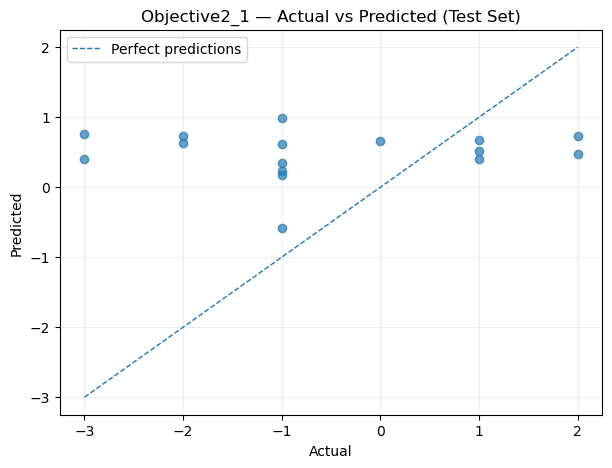

In [10]:
features21 = [
    "X1_PreMatch_GD_Difference",
    "X2_PreMatch_Win_Rate_Difference",
]
model21, metrics21, predictions21 = train_evaluate(
    scatter21,
    features21,
    "Y_Actual_Goal_Difference",
    "Objective2_1",
)


## 10. Linear regression for 2.2

Here I used the team's previous average goals scored and the opponent's previous average goals conceded. I kept both team rows from each match in the same split to make the test fairer.


\nObjective2_2: 128 training rows / 32 testing rows
Train matches: 64; Test matches: 16
Intercept: 0.6916
Coefficients:
X1_Team_PreMatch_Avg_Goals_Scored          0.1731
X2_Opponent_PreMatch_Avg_Goals_Conceded    0.3222
dtype: float64
\nMetrics (lower MAE/RMSE is better; higher R² is better):
   Objective Split  Rows   MAE  RMSE     R2
Objective2_2 Train   128 1.034 1.313  0.085
Objective2_2  Test    32 1.092 1.417 -0.009


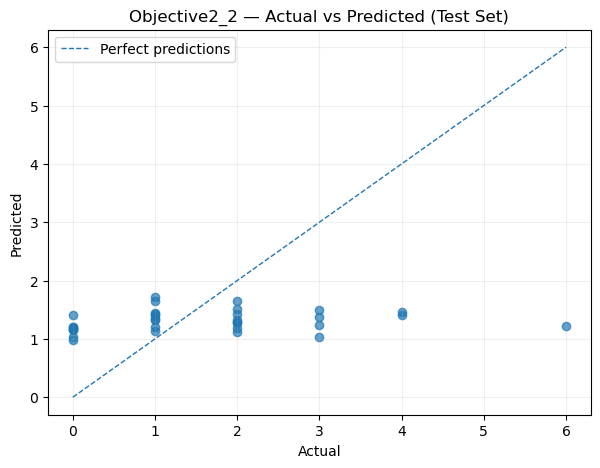

\nBoth preliminary models complete. See outputs/ for metrics, predictions and graphs.


In [11]:
features22 = [
    "X1_Team_PreMatch_Avg_Goals_Scored",
    "X2_Opponent_PreMatch_Avg_Goals_Conceded",
]
model22, metrics22, predictions22 = train_evaluate(
    scatter22,
    features22,
    "Y_Actual_Team_Goals",
    "Objective2_2",
)

print("\\nBoth preliminary models complete. See outputs/ for metrics, predictions and graphs.")
